# 06 - Time patterns

**Question:** how does the generator decide *when* a payment happens (hour, weekday, date)?

Works on the `feat` view through `src/eda.py` (DuckDB session in **UTC**), **normal payments only**. Charts are saved with the prefix `T`.

Local time is not in the data. It is reconstructed from the data itself (C3 below), then compared with official time-zone offsets (IANA time-zone database, used as an external reference for checking only).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda

eda.connect()  # in-memory DuckDB in UTC with views tx (clean) and feat (clean + features). If RAM runs out: eda.connect(memory_limit="3GB")
eda.require_columns("feat", ["sender_country", "party_pair", "utc_hour", "utc_weekday", "utc_date", "usd_amount_log10"])
q, save = eda.q, eda.save

# Normal payments only: the rules in this notebook describe regular traffic (anomalies are in 02_anomaly_types)
eda.con.execute("CREATE OR REPLACE VIEW normal AS SELECT * FROM feat WHERE is_anomaly = 0")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


## 1. Sanity check

In [2]:
checks = q("""
    SELECT count(*)                                AS rows,
           count(*) FILTER (WHERE is_anomaly = 0)  AS normal_rows,
           min(epoch_seconds)                      AS first_payment,
           max(epoch_seconds)                      AS last_payment
    FROM feat
""")
assert checks.loc[0, "rows"] == 10_000_000
assert checks.loc[0, "normal_rows"] == 9_992_994
checks

,rows,normal_rows,first_payment,last_payment
0,10000000,9992994,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


## Hypotheses (written before testing)

| ID | Hypothesis | Test |
|---|---|---|
| H-T1 | Payments follow office hours and working days | Hour and weekday mix in UTC (T1) |
| H-T2 | Sunday is busier than Saturday because some countries (e.g. the Gulf) have a Friday-Saturday weekend | Weekday mix per sender country (T2) |
| H-T3 | Each country follows the same daily pattern in its own local time | Do the countries' UTC hour profiles have one shape, only shifted? Are the shifts the countries' time-zone offsets? (T3) |
| H-T4 | In local time, every region has the same weekly and daily pattern | Weekday and hour mix in reconstructed local time, by region (T4) |
| H-T5 | Businesses and consumers pay at different times, and amounts depend on the time of day | Local hour profile by sender type; amount level by local hour (T5) |
| H-T6 | Volume changes from week to week (e.g. month ends, holidays) | Daily counts and weekly shares, by region and sender type (T6) |

## T1. Hour and weekday in UTC (H-T1)

In [3]:
t1_day = q("""
    SELECT utc_weekday, any_value(utc_weekday_name) AS day, count(*) AS n
    FROM normal GROUP BY 1 ORDER BY 1
""")
t1_day["pct"] = (t1_day.n / t1_day.n.sum() * 100).round(2)
t1_hour = q("SELECT utc_hour, count(*) AS n FROM normal GROUP BY 1 ORDER BY 1")
t1_hour["pct"] = (t1_hour.n / t1_hour.n.sum() * 100).round(2)
display(t1_day)
print(f"UTC hours: quietest {t1_hour.loc[t1_hour.pct.idxmin(), 'utc_hour']}h ({t1_hour.pct.min()}%), "
      f"busiest {t1_hour.loc[t1_hour.pct.idxmax(), 'utc_hour']}h ({t1_hour.pct.max()}%)")

,utc_weekday,day,n,pct
0,0,Mon,1832461,18.34
1,1,Tue,1707243,17.08
2,2,Wed,1703549,17.05
3,3,Thu,1799677,18.01
4,4,Fri,1832420,18.34
5,5,Sat,434597,4.35
6,6,Sun,683047,6.84


UTC hours: quietest 3h (2.18%), busiest 15h (5.86%)


## T2. Weekday mix per sender country, in UTC (H-T2)
Countries with at least 40,000 payments, sorted by their Sunday share.

In [4]:
t2 = q("""
    SELECT sender_country, utc_weekday_name AS day, count(*) AS n
    FROM normal GROUP BY 1, 2
""").pivot(index="sender_country", columns="day", values="n")
t2 = t2[t2.sum(axis=1) >= 40_000]
t2 = (t2.div(t2.sum(axis=1), axis=0) * 100)[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]].round(1)
t2.sort_values("Sun", ascending=False)

day,Mon,Tue,Wed,Thu,Fri,Sat,Sun
sender_country,,,,,,,
AU,18.4,17.0,17.3,18.2,14.4,4.5,10.1
KR,18.4,17.1,17.4,18.2,15.6,4.2,9.1
JP,18.5,16.9,17.2,18.2,15.9,4.2,9.1
CN,18.7,17.0,17.0,18.1,16.7,4.0,8.4
SG,18.7,17.0,17.3,18.1,16.6,3.9,8.4
HK,18.7,17.0,17.2,18.1,16.7,4.0,8.3
MY,18.9,16.9,17.2,18.1,16.6,4.0,8.3
TW,18.5,17.0,17.4,17.9,16.9,4.1,8.2
IN,19.0,17.0,16.9,18.1,18.3,3.8,6.9


## T3. One daily shape, shifted by the time zone (H-T3)
For every country with at least 5,000 payments, the hourly profile (in UTC) is compared with the United Kingdom's profile shifted by k hours (k = -12 ... +12). The best k is the country's offset **relative to the UK**. If the generator uses one local pattern everywhere, the best correlation should be close to 1.

In [5]:
prof = q("SELECT sender_country, utc_hour, count(*) AS n FROM normal GROUP BY 1, 2")
P = prof.pivot(index="sender_country", columns="utc_hour", values="n").fillna(0)
P = P[P.sum(axis=1) >= 5_000]
Pn = P.div(P.sum(axis=1), axis=0)
ref = Pn.loc["GB"].to_numpy()

rows = []
for country, v in Pn.iterrows():
    # If the country runs k hours ahead of the UK, its UTC profile is the UK profile read k hours later:
    # country_utc[h] = GB_utc[h + k], and np.roll(ref, -k)[h] = ref[h + k]
    corr = {k: np.corrcoef(v.to_numpy(), np.roll(ref, -k))[0, 1] for k in range(-12, 13)}
    k = max(corr, key=corr.get)
    rows.append({"country": country, "payments": int(P.loc[country].sum()), "offset_vs_uk": k, "best_corr": corr[k]})
offsets = pd.DataFrame(rows).sort_values("payments", ascending=False).reset_index(drop=True)
print(f"Countries: {len(offsets)}, covering {offsets.payments.sum() / 9_992_994 * 100:.1f}% of normal payments")
print(f"Best correlation: min {offsets.best_corr.min():.3f}, median {offsets.best_corr.median():.4f}")
offsets.head(10).round(3)

Countries: 113, covering 97.9% of normal payments
Best correlation: min 0.934, median 0.9944


,country,payments,offset_vs_uk,best_corr
0,US,1581563,-5,1.000
1,CH,785903,1,1.000
2,GB,662252,0,1.000
3,FR,538477,1,1.000
4,DE,509096,1,1.000
5,SG,392987,8,1.000
6,CN,341599,8,0.999
7,IT,298435,1,1.000
8,BE,295799,1,0.999
9,LU,289965,1,1.000


In [6]:
# Reference: official UTC offsets (IANA time-zone database) in January 2023 and July 2023.
# For countries with several zones the main financial centre is used (US: New York, CA: Toronto, AU: Sydney, RU: Moscow).
TZ = {  # country: (January offset, July offset)
    "US": (-5, -4), "CA": (-5, -4), "PA": (-5, -5), "KY": (-5, -5), "AR": (-3, -3),
    "GB": (0, 1), "IM": (0, 1), "JE": (0, 1), "IE": (0, 1),
    "FR": (1, 2), "DE": (1, 2), "CH": (1, 2), "IT": (1, 2), "BE": (1, 2), "LU": (1, 2), "NL": (1, 2), "AT": (1, 2),
    "ES": (1, 2), "DK": (1, 2), "PL": (1, 2), "CZ": (1, 2), "MC": (1, 2), "LI": (1, 2), "MT": (1, 2),
    "FI": (2, 3), "CY": (2, 3), "UA": (2, 3), "IL": (2, 3), "ZA": (2, 2),
    "TR": (3, 3), "RU": (3, 3), "SA": (3, 3), "QA": (3, 3), "AE": (4, 4), "IN": (5.5, 5.5),
    "CN": (8, 8), "SG": (8, 8), "HK": (8, 8), "MY": (8, 8), "TW": (8, 8), "JP": (9, 9), "KR": (9, 9), "AU": (11, 10),
}
chk = offsets[offsets.country.isin(TZ)].copy()
chk["jan_vs_uk"] = chk.country.map(lambda c: TZ[c][0] - TZ["GB"][0])
chk["jul_vs_uk"] = chk.country.map(lambda c: TZ[c][1] - TZ["GB"][1])
chk["matches_january"] = (chk.offset_vs_uk - chk.jan_vs_uk).abs() <= 0.5
chk["matches_july"] = (chk.offset_vs_uk - chk.jul_vs_uk).abs() <= 0.5
print(f"Estimated offset matches the JANUARY offset for {chk.matches_january.sum()} of {len(chk)} countries "
      f"(India is +5.5: the data only allows whole hours)")
print(f"Estimated offset matches the JULY offset for    {chk.matches_july.sum()} of {len(chk)} countries")
decisive = chk[chk.jan_vs_uk != chk.jul_vs_uk]   # countries whose daylight-saving rules differ from the UK's
print(f"Decisive countries (January and July disagree): {len(decisive)}; matching January: "
      f"{decisive.matches_january.sum()}, matching July: {decisive.matches_july.sum()}")
chk.sort_values("offset_vs_uk").round(3)

Estimated offset matches the JANUARY offset for 43 of 43 countries (India is +5.5: the data only allows whole hours)
Estimated offset matches the JULY offset for    26 of 43 countries
Decisive countries (January and July disagree): 18; matching January: 18, matching July: 1


,country,payments,offset_vs_uk,best_corr,jan_vs_uk,jul_vs_uk,matches_january,matches_july
0,US,1581563,-5,1.000,-5.0,-5.0,True,True
17,CA,124446,-5,1.000,-5.0,-5.0,True,True
25,PA,68077,-5,0.985,-5.0,-6.0,True,False
37,KY,44353,-5,0.992,-5.0,-6.0,True,False
33,AR,50439,-3,0.993,-3.0,-4.0,True,False
24,IE,69821,0,0.998,0.0,0.0,True,True
14,IM,180077,0,0.997,0.0,0.0,True,True
2,GB,662252,0,1.000,0.0,0.0,True,True
32,JE,50897,0,0.998,0.0,0.0,True,True
10,NL,210504,1,0.998,1.0,1.0,True,True


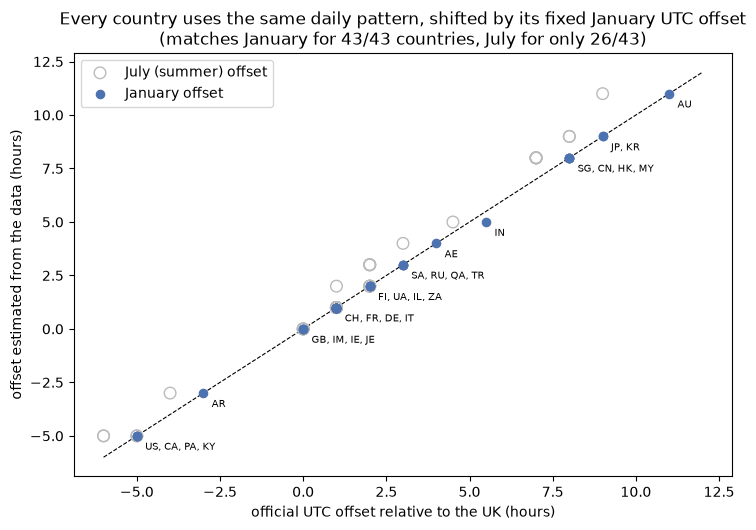

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot([-6, 12], [-6, 12], color="black", lw=0.8, ls="--")
ax.scatter(chk.jul_vs_uk, chk.offset_vs_uk, s=70, facecolors="none", edgecolors="#BBBBBB", label="July (summer) offset", zorder=2)
ax.scatter(chk.jan_vs_uk, chk.offset_vs_uk, s=35, color="#4C72B0", label="January offset", zorder=3)
for _, r in chk.drop_duplicates("jan_vs_uk").iterrows():
    same = ", ".join(chk[chk.jan_vs_uk == r.jan_vs_uk].country.head(4))
    ax.annotate(same, (r.jan_vs_uk, r.offset_vs_uk), textcoords="offset points", xytext=(6, -10), fontsize=7)
ax.set_xlabel("official UTC offset relative to the UK (hours)")
ax.set_ylabel("offset estimated from the data (hours)")
ax.legend(loc="upper left")
ax.set_title(f"Every country uses the same daily pattern, shifted by its fixed January UTC offset\n"
             f"(matches January for {chk.matches_january.sum()}/{len(chk)} countries, July for only {chk.matches_july.sum()}/{len(chk)})")
save(fig, "T3_time_zone_offsets")
plt.show()

## T4. Local time (H-T4)
Local time = UTC + the offset estimated in T3 (the UK = UTC, as in January). Regions are defined by that offset. Countries with fewer than 5,000 payments are left out.

In [8]:
eda.con.register("offsets_df", offsets[["country", "offset_vs_uk"]])
eda.con.execute("CREATE OR REPLACE TEMP TABLE offsets AS SELECT country AS sender_country, offset_vs_uk AS offset_h FROM offsets_df")
eda.con.execute("""
    CREATE OR REPLACE TEMP VIEW local_time AS
    SELECT n.*,
           n.epoch_seconds + to_hours(o.offset_h) AS local_ts,
           CASE WHEN o.offset_h <= -3 THEN '1 Americas (UTC-5 to -3)'
                WHEN o.offset_h <= 2  THEN '2 Europe / Africa (UTC+0 to +2)'
                WHEN o.offset_h <= 6  THEN '3 Middle East / South Asia (UTC+3 to +6)'
                ELSE                       '4 Asia-Pacific (UTC+7 to +11)' END AS region
    FROM normal n JOIN offsets o USING (sender_country)
""")
t4_day = q("""
    SELECT region, isodow(local_ts) AS local_weekday, count(*) AS n
    FROM local_time GROUP BY 1, 2
""").pivot(index="region", columns="local_weekday", values="n")
t4_day = (t4_day.div(t4_day.sum(axis=1), axis=0) * 100).round(1)
t4_day.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
t4_utc = (t2.loc[t2.index.isin(["US", "GB", "SA", "JP"])])
display(t4_day)  # local time: % of each region's payments per weekday
t4_utc  # for comparison: the same weekday mix in UTC for one country per region

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
region,,,,,,,
1 Americas (UTC-5 to -3),19.0,17.0,17.0,18.0,18.8,3.5,6.6
2 Europe / Africa (UTC+0 to +2),18.9,17.0,17.0,18.0,19.0,3.6,6.5
3 Middle East / South Asia (UTC+3 to +6),18.9,17.1,16.9,18.1,18.9,3.6,6.5
4 Asia-Pacific (UTC+7 to +11),18.8,17.0,17.0,17.9,19.0,3.8,6.4


day,Mon,Tue,Wed,Thu,Fri,Sat,Sun
sender_country,,,,,,,
GB,18.9,17.0,17.0,18.0,19.1,3.5,6.5
JP,18.5,16.9,17.2,18.2,15.9,4.2,9.1
SA,18.7,17.2,16.9,18.1,18.5,3.7,6.7
US,16.5,17.3,17.0,17.8,18.7,6.6,6.0


In [9]:
t4_hour = q("""
    SELECT hour(local_ts) AS local_hour, ordering_type AS sender_type, count(*) AS n
    FROM local_time GROUP BY 1, 2
""").pivot(index="local_hour", columns="sender_type", values="n")
t4_hour = t4_hour / t4_hour.sum() * 100
t4_hour["all"] = t4_hour.mean(axis=1)
office = t4_hour.loc[7:18].sum()
print(f"Share of payments between 07:00 and 18:59 local time: {office['B']:.1f}% (business senders), {office['C']:.1f}% (consumer senders)")
print(f"Night 00:00-05:59: {t4_hour.loc[0:5].sum()['B']:.1f}% (business), {t4_hour.loc[0:5].sum()['C']:.1f}% (consumer)")
print(f"Correlation of the business and consumer hour profiles: {np.corrcoef(t4_hour['B'], t4_hour['C'])[0, 1]:.4f}")
t4_hour.round(2).T

Share of payments between 07:00 and 18:59 local time: 71.6% (business senders), 69.6% (consumer senders)
Night 00:00-05:59: 7.1% (business), 7.2% (consumer)
Correlation of the business and consumer hour profiles: 0.9908


local_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
sender_type,,,,,,,,,,,,,,,,,,,,,,,,
B,1.86,1.08,1.01,1.00,0.98,1.11,2.30,7.48,6.21,5.19,5.68,4.56,4.27,5.42,4.74,5.53,7.66,7.38,7.51,6.30,4.82,3.42,2.83,1.64
C,1.92,1.13,1.03,1.03,1.01,1.10,2.20,7.60,5.71,4.81,5.42,4.39,4.19,5.25,4.49,5.27,7.02,7.41,8.08,6.93,5.35,3.76,3.13,1.78
all,1.89,1.11,1.02,1.01,1.00,1.11,2.25,7.54,5.96,5.00,5.55,4.48,4.23,5.33,4.61,5.40,7.34,7.40,7.79,6.62,5.08,3.59,2.98,1.71


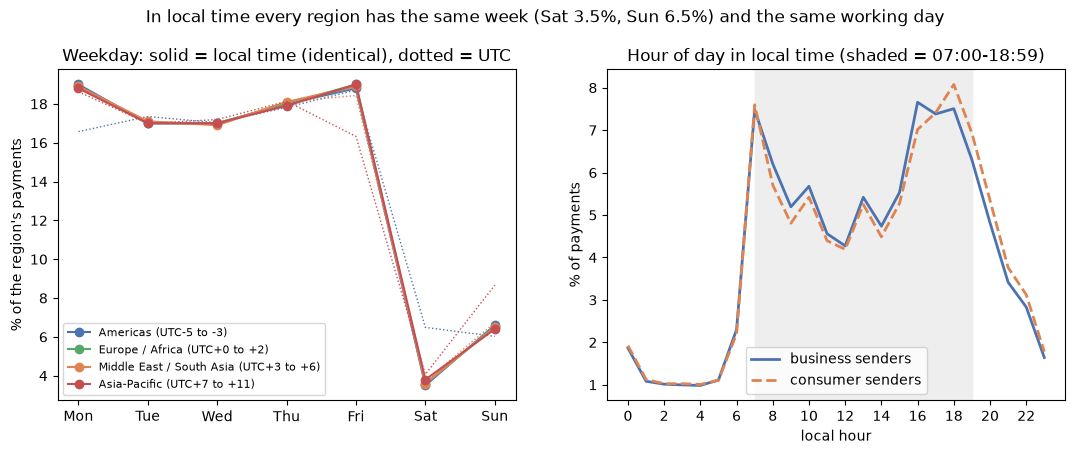

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
utc_by_region = q("""
    SELECT region, utc_weekday AS d, count(*) AS n FROM local_time GROUP BY 1, 2
""").pivot(index="d", columns="region", values="n")
utc_by_region = utc_by_region / utc_by_region.sum() * 100
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cols = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
for c, col in zip(t4_day.index, cols):
    axes[0].plot(days, t4_day.loc[c], marker="o", color=col, label=c[2:])
    axes[0].plot(days, utc_by_region[c].to_numpy(), color=col, ls=":", lw=1)
axes[0].set_ylabel("% of the region's payments")
axes[0].set_title("Weekday: solid = local time (identical), dotted = UTC")
axes[0].legend(fontsize=8)
axes[1].plot(t4_hour.index, t4_hour["B"], color="#4C72B0", lw=2, label="business senders")
axes[1].plot(t4_hour.index, t4_hour["C"], color="#DD8452", lw=2, ls="--", label="consumer senders")
axes[1].axvspan(7, 19, color="#EEEEEE", zorder=0)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("local hour")
axes[1].set_ylabel("% of payments")
axes[1].set_title("Hour of day in local time (shaded = 07:00-18:59)")
axes[1].legend()
fig.suptitle("In local time every region has the same week (Sat 3.5%, Sun 6.5%) and the same working day", y=1.02)
save(fig, "T4_local_time")
plt.show()

## T5. Is time linked to amount? (H-T5)
Amount level (log10, party-pair and sender-country means removed) by local hour band and by local weekday.

In [11]:
t5 = q("""
    WITH m AS (SELECT party_pair, sender_country, avg(usd_amount_log10) AS m FROM normal GROUP BY 1, 2)
    SELECT 'local hour band' AS dimension,
           CASE WHEN hour(local_ts) < 6 THEN '00-05' WHEN hour(local_ts) < 12 THEN '06-11'
                WHEN hour(local_ts) < 18 THEN '12-17' ELSE '18-23' END AS value,
           count(*) AS n, avg(usd_amount_log10 - m.m) AS amount_level
    FROM local_time JOIN m USING (party_pair, sender_country) GROUP BY 2
    UNION ALL
    SELECT 'local weekday', CAST(isodow(local_ts) AS VARCHAR), count(*), avg(usd_amount_log10 - m.m)
    FROM local_time JOIN m USING (party_pair, sender_country) GROUP BY 2
    ORDER BY 1, 2
""")
t5.round(4)  # log10 units: 0.01 = 2% larger

,dimension,value,n,amount_level
0,local hour band,00-05,693618,-0.0013
1,local hour band,06-11,3046383,0.0010
2,local hour band,12-17,3394930,0.0007
3,local hour band,18-23,2646088,-0.0017
4,local weekday,1,1851815,0.0008
5,local weekday,2,1663508,-0.0006
6,local weekday,3,1664082,0.0004
7,local weekday,4,1760124,0.0002
8,local weekday,5,1852785,-0.0007
9,local weekday,6,350959,-0.0014


## T6. Day-to-day volume (H-T6)
Weeks run Monday-Sunday (UTC). Only the 13 full weeks (1 May - 30 July) are used.

In [12]:
t6_shape = q("""
    WITH d AS (SELECT date_trunc('week', epoch_seconds)::DATE AS week, utc_weekday, count(*) AS n
               FROM normal WHERE epoch_seconds >= '2023-05-01' AND epoch_seconds < '2023-07-31' GROUP BY 1, 2),
    w AS (SELECT week, sum(n) AS week_total FROM d GROUP BY 1)
    SELECT utc_weekday, 100 * avg(n / week_total) AS mean_share_pct, 100 * stddev(n / week_total) AS sd_across_weeks,
           count(*) AS weeks
    FROM d JOIN w USING (week) GROUP BY 1 ORDER BY 1
""")
display(t6_shape.round(3))  # weekday 0 = Monday
t6_week = q("""
    WITH r AS (
        SELECT date_trunc('week', l.epoch_seconds)::DATE AS week, l.region, l.ordering_type
        FROM local_time l WHERE l.epoch_seconds >= '2023-05-01' AND l.epoch_seconds < '2023-07-31'
    )
    SELECT week, region, ordering_type, count(*) AS n FROM r GROUP BY ALL
""")
by_region = t6_week.pivot_table(index="week", columns="region", values="n", aggfunc="sum")
by_type = t6_week.pivot_table(index="week", columns="ordering_type", values="n", aggfunc="sum")
t6 = pd.concat([by_region / by_region.sum() * 100, (by_type / by_type.sum() * 100).add_prefix("sender ")], axis=1)
t6["max_minus_min"] = t6.max(axis=1) - t6.min(axis=1)
t6.round(2)  # % of each group's volume falling in each week

,utc_weekday,mean_share_pct,sd_across_weeks,weeks
0,0,18.330,0.089,13
1,1,17.086,0.071,13
2,2,17.051,0.080,13
3,3,18.014,0.066,13
4,4,18.345,0.086,13
5,5,4.350,0.041,13
6,6,6.823,0.329,13


,1 Americas (UTC-5 to -3),2 Europe / Africa (UTC+0 to +2),3 Middle East / South Asia (UTC+3 to +6),4 Asia-Pacific (UTC+7 to +11),sender B,sender C,max_minus_min
week,,,,,,,
2023-05-01,7.43,7.48,7.48,7.44,7.46,7.48,0.05
2023-05-08,5.01,5.00,4.97,5.03,5.00,5.01,0.06
2023-05-15,5.01,5.01,5.02,5.17,5.04,5.03,0.16
2023-05-22,8.47,8.49,8.53,8.56,8.50,8.50,0.09
2023-05-29,8.53,8.50,8.49,8.49,8.50,8.51,0.04
2023-06-05,7.51,7.51,7.50,7.53,7.52,7.49,0.03
2023-06-12,8.47,8.54,8.55,8.67,8.55,8.53,0.20
2023-06-19,12.00,12.00,12.01,11.93,11.99,11.98,0.08
2023-06-26,9.53,9.49,9.49,9.37,9.48,9.48,0.16


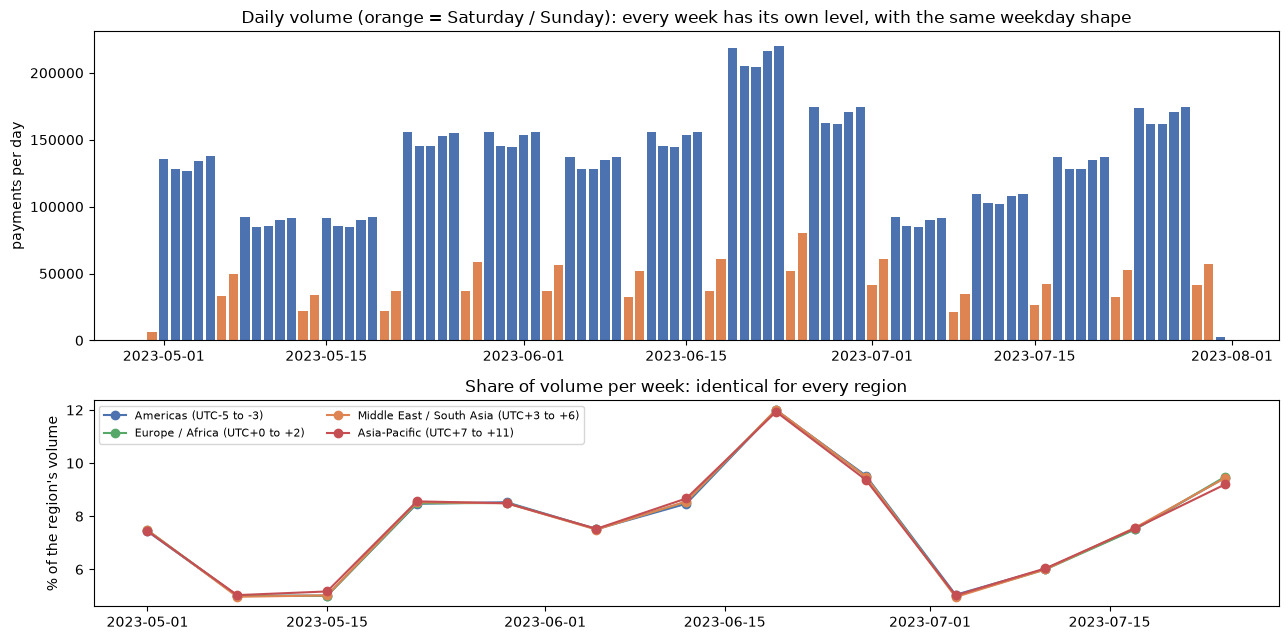

In [13]:
daily = q("""
    SELECT utc_date, any_value(utc_weekday) AS wd, count(*) AS n
    FROM normal GROUP BY 1 ORDER BY 1
""")
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), gridspec_kw={"height_ratios": [3, 2]})
axes[0].bar(daily.utc_date, daily.n, color=np.where(daily.wd >= 5, "#DD8452", "#4C72B0"), width=0.8)
axes[0].set_ylabel("payments per day")
axes[0].set_title("Daily volume (orange = Saturday / Sunday): every week has its own level, with the same weekday shape")
for c, col in zip(by_region.columns, ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]):
    axes[1].plot(t6.index, t6[c], marker="o", color=col, label=c[2:])
axes[1].set_ylabel("% of the region's volume")
axes[1].set_title("Share of volume per week: identical for every region")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "T6_weekly_levels")
plt.show()

## T7. Results → rules (verified on all 9,992,994 normal payments)

| ID | Rule (condition → effect → size → rows covered) | Evidence | Confidence |
|---|---|---|---|
| R-T1 | Payment times are generated in the **sender's local time** with **one common pattern for every country**: each country's UTC hour profile is the same shape, only shifted (best correlation median **0.994**, minimum 0.934, over 113 countries = **97.9%** of normal payments). | T3 | High |
| R-T2 | The shift is the country's **fixed January UTC offset**, used for the whole May-July period (no daylight-saving time): it matches January for **43 of 43** reference countries (US/CA/PA/KY -5, AR -3, UK 0, central Europe +1, FI/IL/UA/CY/ZA +2, SA/RU/QA/TR +3, AE +4, China region +8, JP/KR +9, AU +11). Among the **18** countries where January and July disagree, all 18 follow January; July fits only India, whose half-hour offset (+5.5) cannot be resolved with whole hours. | T3 | High |
| R-T3 | In local time the **week is identical in every region**: Mon 18.8-19.0%, Tue 17.0-17.1%, Wed 16.9-17.0%, Thu 17.9-18.1%, Fri 18.8-19.0%, **Sat 3.5-3.8%**, **Sun 6.4-6.6%**. **Sunday has about 1.8x Saturday's volume** everywhere. | T2, T4 | High |
| R-T4 | In local time the day is a **working day**: about **1% per hour at night** (00:00-05:59 = 7.1-7.2% in total), a jump to **7.5% at 07:00**, and a peak of **7.3-7.8% per hour between 16:00 and 18:59**; **69.6-71.6%** of payments fall between 07:00 and 18:59. Businesses and consumers share the same profile (correlation 0.991); consumers are slightly later in the evening. | T4 | High |
| R-T5 | **Time and amount are independent**: with party pair and sender country removed, the amount level differs by less than 0.002 log10 (under 0.5%) between local hour bands and weekdays. | T5 | High |
| R-T6 | **Each week has its own volume level, applied to everyone at once**: a week holds 5.0% to 12.0% of all payments, and that share is the same for all 4 regions and both sender types (largest difference 0.29 points). Inside a week the weekday shape is fixed (Mon-Sat shares have a standard deviation of at most 0.09 points across weeks). | T6 | High (observation) |

**Hypotheses that did not hold:**
- H-T2 "Sunday is busier because of Friday-Saturday weekends": rejected. Saudi Arabia, Qatar and the UAE have the same weekday mix as Europe (Friday 18.4-18.6%). In UTC, Sunday looks busier because Asia-Pacific's Monday morning falls on Sunday UTC (AU 10.1%), and Saturday looks busier for the Americas because their Friday evening falls on Saturday UTC (US 6.6%). In local time both effects disappear, but Sunday stays 1.8x Saturday (R-T3).
- H-T5 "businesses and consumers pay at different times": rejected (correlation 0.991).
- H-T5 "amounts depend on the time": rejected (R-T5).
- H-T1 in UTC: the "busiest hour 15:00 UTC" is only the sum of shifted local working days, not a rule of its own.

**Still unexplained / limits:** what sets each week's level (5.0%, 6.0%, 7.5%, 8.5%, 9.5% or 12.0% of the total; no link to month ends found). The offsets are measured relative to the UK and assume the UK runs on UTC, as it does in January. Countries with fewer than 5,000 payments (2.1% of volume) get no offset. The US and Australia span several time zones, but the data fits one offset per country (New York, Sydney). The Sunday share varies more between UTC weeks (standard deviation 0.33 points) because a UTC Sunday contains part of the next local week in Asia-Pacific.